# 02 - Exploratory Data Analysis (cleaned H2)
Continues `01_data_understanding_cleaning`. Cells are numbered from 7 so they can also be pasted at the end of notebook 01.

**Rule for this notebook:** EDA only *looks* at the data. Nothing here changes `df_clean`, and nothing learned here
(means, quantiles, thresholds) is fed into a model. Data-dependent preprocessing stays in the Pipeline, fitted on train only.

**What this does:** if you run this notebook on its own, it rebuilds `df_clean` by calling the same cleaning module (no copy of the logic).
If you pasted it after notebook 01, `df_clean` already exists and the block is skipped.

In [1]:
# Cell 7 - setup. Skips the rebuild if df_clean already exists (pasted after notebook 01).
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'H2.csv').is_file():
    PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_FIGURES = PROJECT_ROOT / 'outputs' / 'figures'
OUTPUT_TABLES = PROJECT_ROOT / 'outputs' / 'tables'
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

if 'df_clean' not in globals():
    from src.preprocessing.cleaning import clean_from_description
    _raw = pd.read_csv(PROJECT_ROOT / 'data' / 'H2.csv')
    df_clean, _ = clean_from_description('config/datasets/h2.yaml', project_root=PROJECT_ROOT, df=_raw, save=False)
print(f'df_clean ready: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')

df_clean ready: 53,042 rows x 31 columns


In [2]:
# Cell 8 - column groups and a figure-saving helper
TARGET_CLS = 'IsCanceled'   # classification target
TARGET_REG = 'ADR'          # regression target
BINARY_COLS = ['IsCanceled', 'IsRepeatedGuest']
ID_COLS = [c for c in ['Agent', 'Company'] if c in df_clean.columns]   # IDs are labels, never quantities

# Agent/Company are forced into the categorical group even if cleaning left them as floats with NaN.
_cat_auto = df_clean.select_dtypes(exclude=['number', 'datetime']).columns.tolist()
cat_cols = [c for c in _cat_auto if c not in ID_COLS] + ID_COLS
num_cols = [c for c in df_clean.select_dtypes(include='number').columns
            if c not in BINARY_COLS and c not in ID_COLS]
date_cols = df_clean.select_dtypes(include='datetime').columns.tolist()

MONTH_ORDER = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
               'August', 'September', 'October', 'November', 'December']

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_FIGURES / f'{name}.png', dpi=150)

print(f'{len(num_cols)} numeric | {len(BINARY_COLS)} binary | {len(cat_cols)} categorical | {len(date_cols)} date')

16 numeric | 2 binary | 13 categorical | 0 date


**What this does:** splits the columns into groups once, so every later cell reuses them. `Agent` and `Company` are IDs stored as text, so they land in the categorical group (correct: an ID is a label, not a quantity).
`save_fig` saves every figure into `outputs/figures` so it can go straight into the report.

In [3]:
# Cell 9 - overview table: types, missing values, cardinality
overview = pd.DataFrame({
    'dtype': df_clean.dtypes.astype(str),
    'missing': df_clean.isna().sum(),
    'missing_%': (df_clean.isna().mean() * 100).round(2),
    'n_unique': df_clean.nunique(),
})
display(overview)
print(f'Duplicate rows left: {df_clean.duplicated().sum()}')
overview.to_csv(OUTPUT_TABLES / 'eda_overview.csv')

,dtype,missing,missing_%,n_unique
IsCanceled,int64,0,0.00,2
LeadTime,int64,0,0.00,453
ArrivalDateYear,int64,0,0.00,3
ArrivalDateMonth,object,0,0.00,12
ArrivalDateWeekNumber,int64,0,0.00,53
ArrivalDateDayOfMonth,int64,0,0.00,31
StaysInWeekendNights,int64,0,0.00,12
StaysInWeekNights,int64,0,0.00,26
Adults,int64,0,0.00,5
Children,float64,4,0.01,4


Duplicate rows left: 0


**What this does:** one table answering the spec's first checklist item (dimensions, types, duplicates, missing values, cardinality).
Look at `n_unique`: `Country`, `Agent` and `Company` have many categories, so plain one-hot encoding will create many columns later.

In [4]:
# Cell 10 - numeric summary statistics and skewness
num_summary = df_clean[num_cols].describe().T
num_summary['skew'] = df_clean[num_cols].skew()
num_summary['kurtosis'] = df_clean[num_cols].kurt()
num_summary = num_summary.round(2)
display(num_summary)
print('Strongly skewed (|skew| > 1):', num_summary.index[num_summary['skew'].abs() > 1].tolist())
num_summary.to_csv(OUTPUT_TABLES / 'eda_numeric_summary.csv')

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
LeadTime,53042.0,78.04,82.14,0.0,14.0,51.00,118.0,629.0,1.57,3.10
ArrivalDateYear,53042.0,2016.26,0.66,2015.0,2016.0,2016.00,2017.0,2017.0,-0.33,-0.77
ArrivalDateWeekNumber,53042.0,26.63,13.57,1.0,16.0,27.00,37.0,53.0,0.06,-0.94
ArrivalDateDayOfMonth,53042.0,15.76,8.80,1.0,8.0,16.00,23.0,31.0,0.01,-1.20
StaysInWeekendNights,53042.0,0.87,0.90,0.0,0.0,1.00,2.0,14.0,1.00,3.52
StaysInWeekNights,53042.0,2.28,1.58,0.0,1.0,2.00,3.0,34.0,2.52,19.93
Adults,53042.0,1.88,0.54,0.0,2.0,2.00,2.0,4.0,-0.24,0.84
Children,53038.0,0.13,0.44,0.0,0.0,0.00,0.0,3.0,3.48,11.52
Babies,53042.0,0.01,0.10,0.0,0.0,0.00,0.0,10.0,36.88,2863.10
PreviousCancellations,53042.0,0.04,0.37,0.0,0.0,0.00,0.0,21.0,22.84,710.88


Strongly skewed (|skew| > 1): ['LeadTime', 'StaysInWeekNights', 'Children', 'Babies', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'BookingChanges', 'DaysInWaitingList', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests']


**What this does:** `describe()` gives min / quartiles / max; skew tells how lopsided each variable is (0 = symmetric, above 1 = long right tail).
Skewed variables matter for models that assume roughly normal inputs (linear models, KNN, SVM), so we decide later whether to transform them.

In [5]:
# Cell 11 - categorical cardinality and dominant category
rows = []
for c in cat_cols:
    vc = df_clean[c].value_counts(dropna=True)
    rows.append({'column': c, 'n_categories': len(vc), 'top_category': vc.index[0],
                 'top_share_%': round(vc.iloc[0] / vc.sum() * 100, 1)})
cat_summary = pd.DataFrame(rows).set_index('column').sort_values('n_categories', ascending=False)
display(cat_summary)
cat_summary.to_csv(OUTPUT_TABLES / 'eda_categorical_summary.csv')

,n_categories,top_category,top_share_%
column,,,
ReservationStatusDate,864,2015-10-21,0.3
Agent,223,9,60.2
Company,203,40,30.7
Country,166,PRT,24.4
ArrivalDateMonth,12,August,12.4
MarketSegment,8,Online TA,65.7
AssignedRoomType,8,A,62.7
ReservedRoomType,7,A,71.0
DistributionChannel,5,TA/TO,83.5


**What this does:** for each text column, how many categories it has and how dominant the biggest one is.
High cardinality (`Agent`, `Company`, `Country`) needs a special encoding strategy; a very dominant category (for example `Company`) may carry little information except "present or not".

In [6]:
# Cell 12 - unusual / suspicious values (we only COUNT them here; no row is removed)
checks = {
    'ADR == 0 (complimentary or free stays?)': (df_clean['ADR'] == 0).sum(),
    'ADR > 300': (df_clean['ADR'] > 300).sum(),
    'Zero nights (weekend + week = 0)': ((df_clean['StaysInWeekendNights'] + df_clean['StaysInWeekNights']) == 0).sum(),
    'LeadTime > 365 days': (df_clean['LeadTime'] > 365).sum(),
    'Adults > 4': (df_clean['Adults'] > 4).sum(),
    'Babies > 0': (df_clean['Babies'] > 0).sum(),
    'DaysInWaitingList > 0': (df_clean['DaysInWaitingList'] > 0).sum(),
    'AssignedRoomType != ReservedRoomType': (df_clean['AssignedRoomType'] != df_clean['ReservedRoomType']).sum(),
}
unusual = pd.Series(checks, name='rows').to_frame()
unusual['share_%'] = (unusual['rows'] / len(df_clean) * 100).round(2)
display(unusual)
print('Arrival years:', sorted(df_clean['ArrivalDateYear'].unique()))
unusual.to_csv(OUTPUT_TABLES / 'eda_unusual_values.csv')

,rows,share_%
ADR == 0 (complimentary or free stays?),722,1.36
ADR > 300,42,0.08
Zero nights (weekend + week = 0),0,0.00
LeadTime > 365 days,375,0.71
Adults > 4,0,0.00
Babies > 0,366,0.69
DaysInWaitingList > 0,714,1.35
AssignedRoomType != ReservedRoomType,5871,11.07


Arrival years: [np.int64(2015), np.int64(2016), np.int64(2017)]


**What this does:** the spec asks for "invalid or unusual values". These are judgement checks, not automatic deletions.
Note `AssignedRoomType != ReservedRoomType`: a room can only be *assigned* at check-in, which is a leakage hint we will use in the leakage table.

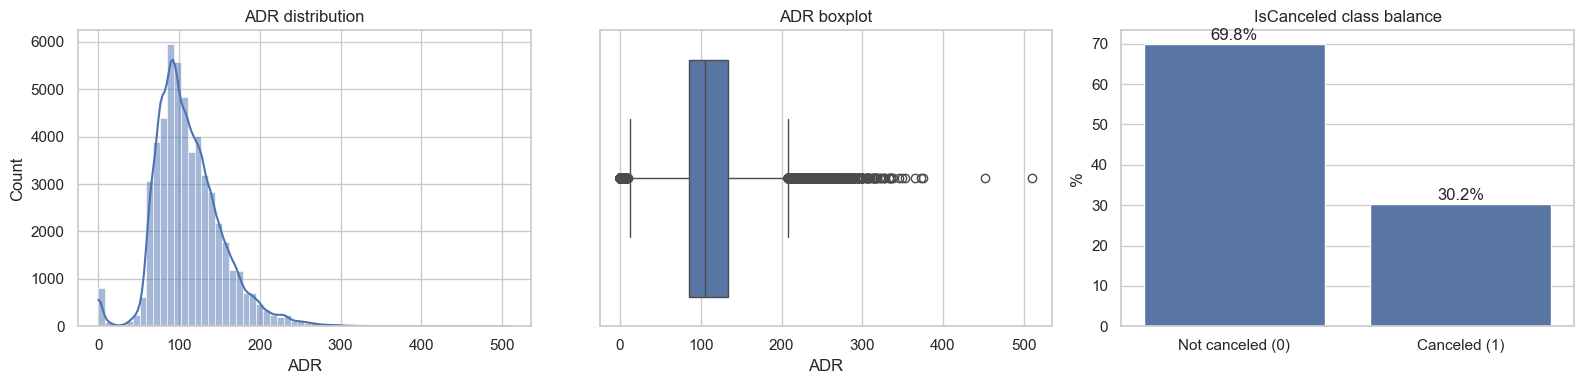

ADR skew: 0.76 | mean 111.7 | median 105.7


In [7]:
# Cell 13 - the two targets: ADR (regression) and IsCanceled (classification)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df_clean['ADR'], bins=60, kde=True, ax=axes[0]); axes[0].set_title('ADR distribution')
sns.boxplot(x=df_clean['ADR'], ax=axes[1]); axes[1].set_title('ADR boxplot')
rate = df_clean['IsCanceled'].value_counts(normalize=True).sort_index() * 100
sns.barplot(x=['Not canceled (0)', 'Canceled (1)'], y=rate.values, ax=axes[2])
for i, v in enumerate(rate.values):
    axes[2].text(i, v + 1, f'{v:.1f}%', ha='center')
axes[2].set_title('IsCanceled class balance'); axes[2].set_ylabel('%')
save_fig(fig, 'eda_targets')
plt.show()
print(f"ADR skew: {df_clean['ADR'].skew():.2f} | mean {df_clean['ADR'].mean():.1f} | median {df_clean['ADR'].median():.1f}")

**What this does:** looks at what we are trying to predict.
- **ADR:** if the mean is above the median and the boxplot has a long right tail, the distribution is right-skewed. Models with squared error are sensitive to that tail.
- **IsCanceled:** shows the class balance. If it is far from 50/50, accuracy alone is a misleading metric, so we will also use precision, recall, F1 and ROC-AUC (all required by the spec).

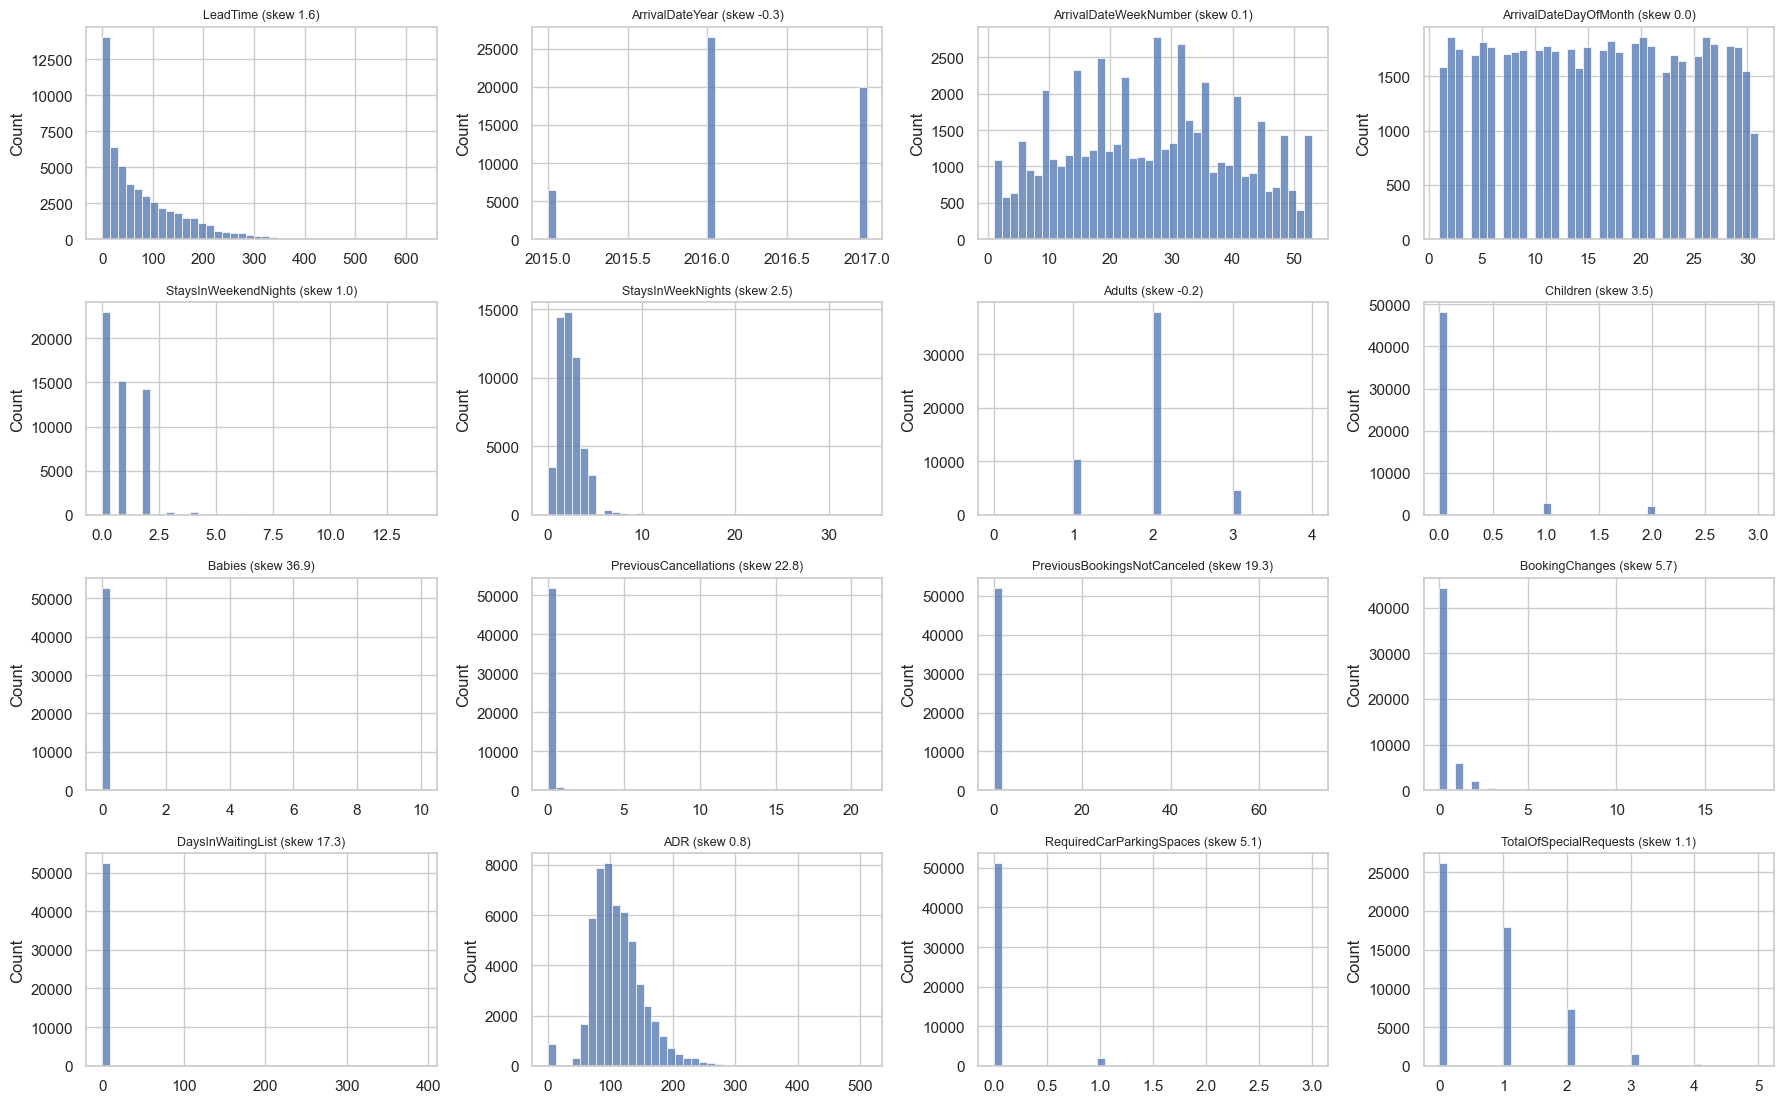

In [8]:
# Cell 14 - histograms of all numeric features (grid size adapts to the column count)
n_cols_grid = 4
n_rows_grid = int(np.ceil(len(num_cols) / n_cols_grid))
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(18, 2.8 * n_rows_grid), squeeze=False)
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_clean[col], bins=40, ax=ax)
    ax.set_title(f"{col} (skew {df_clean[col].skew():.1f})", fontsize=9)
    ax.set_xlabel('')
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
save_fig(fig, 'eda_numeric_histograms')
plt.show()

**What this does:** one histogram per numeric column so you can see which ones are heavily skewed or mostly zeros
(`Babies`, `PreviousCancellations`, `DaysInWaitingList` are typical). Mostly-zero columns are better treated as "has / has not" flags or left alone for tree models.

In [9]:
# Cell 15 - outlier summary with the IQR rule (for LOOKING only, not removing)
rows = []
for c in num_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df_clean[c] < low) | (df_clean[c] > high)).sum())
    rows.append({'column': c, 'lower_fence': round(low, 2), 'upper_fence': round(high, 2),
                 'n_outliers': n_out, 'outlier_%': round(n_out / len(df_clean) * 100, 2)})
outliers = pd.DataFrame(rows).set_index('column').sort_values('outlier_%', ascending=False)
display(outliers)
outliers.to_csv(OUTPUT_TABLES / 'eda_outliers_iqr.csv')

,lower_fence,upper_fence,n_outliers,outlier_%
column,,,,
Adults,2.00,2.00,15192,28.64
BookingChanges,0.00,0.00,8703,16.41
Children,0.00,0.00,4926,9.29
ADR,11.35,207.75,2218,4.18
RequiredCarParkingSpaces,0.00,0.00,1888,3.56
LeadTime,-142.00,274.00,1694,3.19
TotalOfSpecialRequests,-1.50,2.50,1672,3.15
PreviousBookingsNotCanceled,0.00,0.00,1516,2.86
PreviousCancellations,0.00,0.00,1171,2.21


**What this does:** counts how many values fall outside the IQR fences. We do **not** drop them: in booking data a long `LeadTime` or a high `ADR` in peak season is often real.
Fences computed from the whole data are fine for *describing*; they must not be used as a cleaning rule (that is why the cleaning step uses fixed ADR limits).

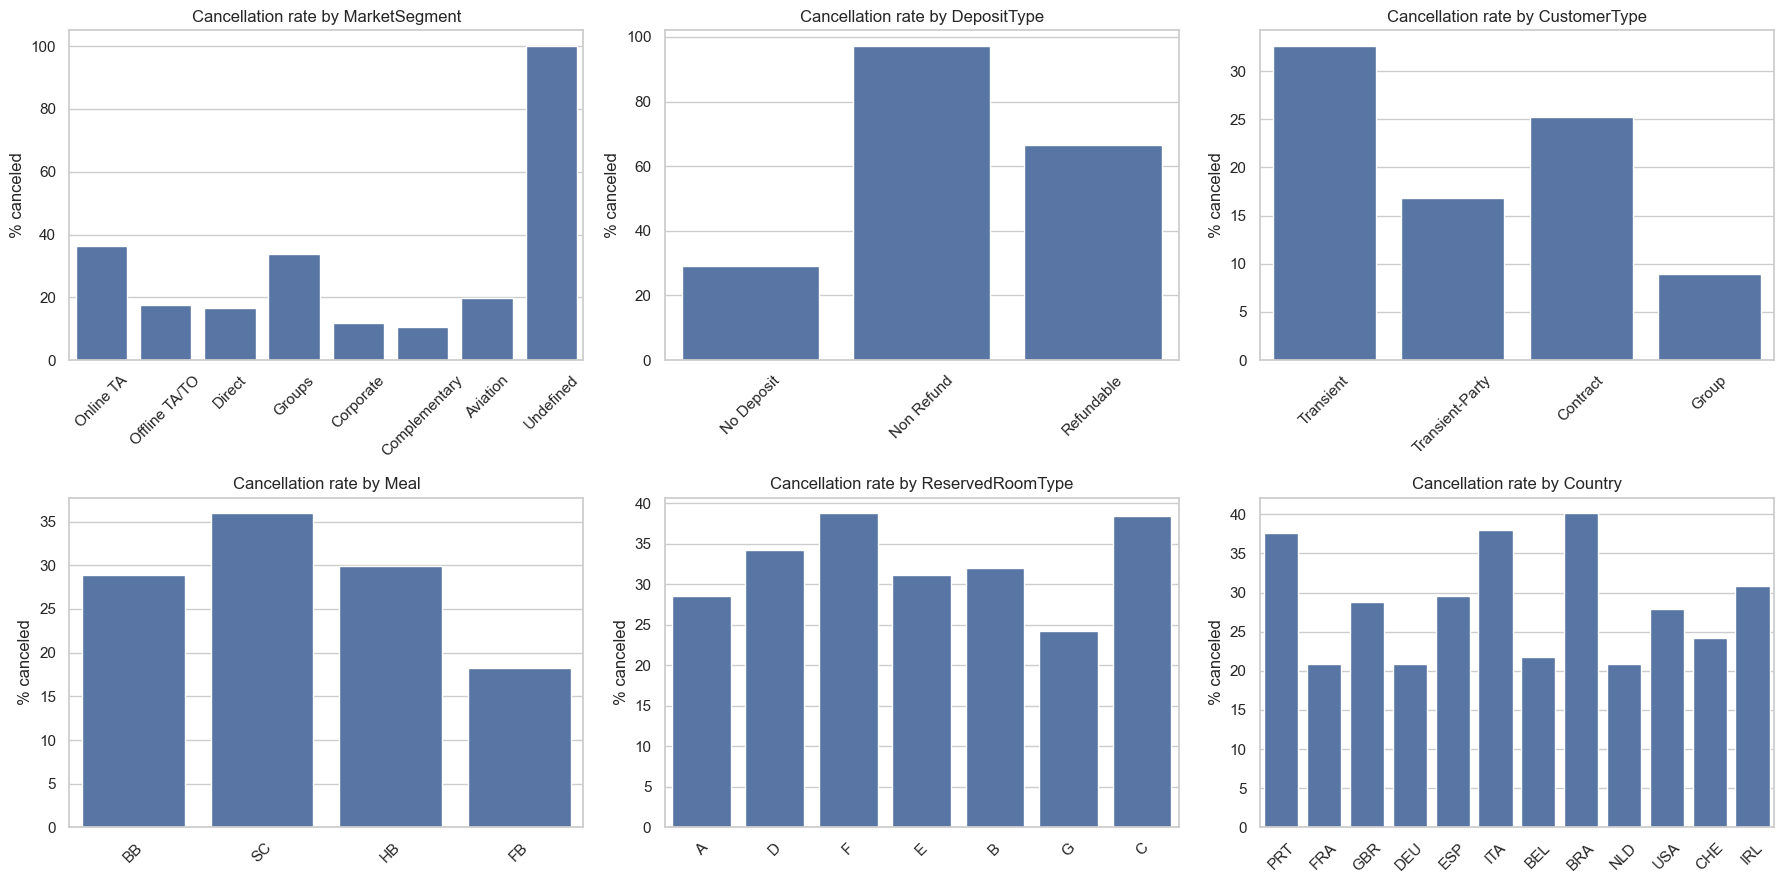

,cancel_rate,n
Country,,
PRT,0.377,12932
FRA,0.209,7394
GBR,0.287,4514
DEU,0.209,4465
ESP,0.296,3775
ITA,0.380,2640
BEL,0.217,1690
BRA,0.401,1583
NLD,0.209,1429


In [10]:
# Cell 16 - cancellation rate by key categorical features
def plot_cancel_rate(col, ax, top=None):
    stats = (df_clean.groupby(col)['IsCanceled'].agg(['mean', 'size'])
             .rename(columns={'mean': 'cancel_rate', 'size': 'n'})
             .sort_values('n', ascending=False))
    if top:
        stats = stats.head(top)
    sns.barplot(x=stats.index.astype(str), y=stats['cancel_rate'] * 100, ax=ax)
    ax.set_title(f'Cancellation rate by {col}'); ax.set_ylabel('% canceled'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
    return stats

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ['MarketSegment', 'DepositType', 'CustomerType', 'Meal', 'ReservedRoomType']):
    plot_cancel_rate(col, ax)
country_stats = plot_cancel_rate('Country', axes.ravel()[5], top=12)
save_fig(fig, 'eda_cancel_rate_by_category')
plt.show()
display(country_stats.round(3))

**What this does:** shows which categories are linked to more cancellations (the last panel is the 12 most common countries).
These are first impressions of which features may be useful for classification. A surprising result here (for example a refundable-looking deposit type with very high cancellations) should be explained in the report, not ignored.

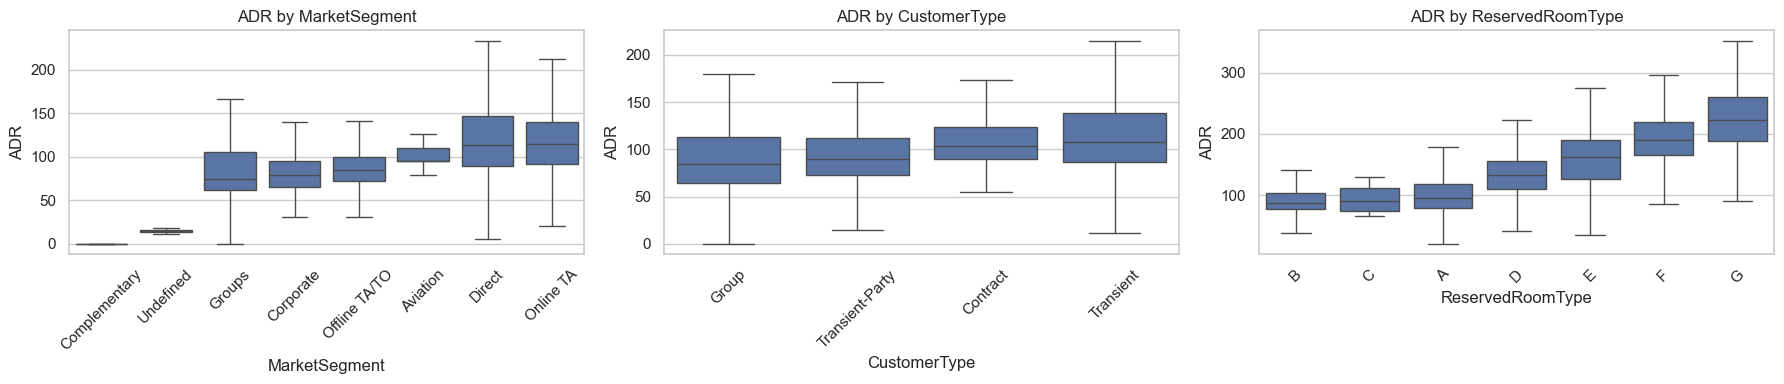

In [11]:
# Cell 17 - ADR by key categorical features
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['MarketSegment', 'CustomerType', 'ReservedRoomType']):
    order = df_clean.groupby(col)['ADR'].median().sort_values().index
    sns.boxplot(data=df_clean, x=col, y='ADR', order=order, ax=ax, showfliers=False)
    ax.set_title(f'ADR by {col}'); ax.tick_params(axis='x', rotation=45)
save_fig(fig, 'eda_adr_by_category')
plt.show()

**What this does:** compares the ADR distribution across categories (outliers hidden so the boxes stay readable).
Large differences between boxes mean the column is probably a useful regression predictor.

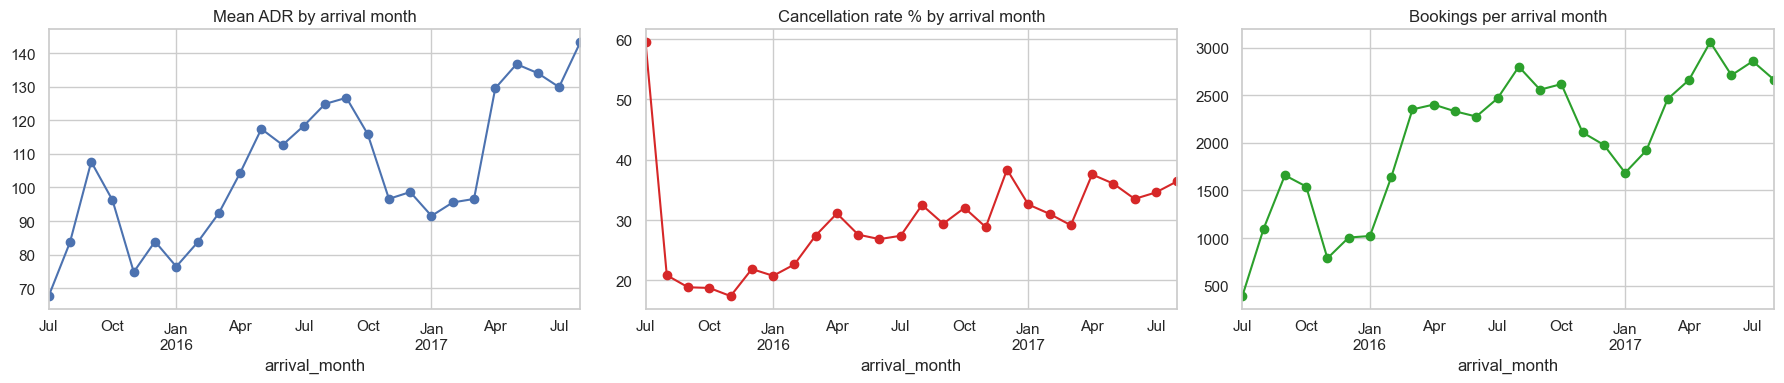

In [12]:
# Cell 18 - seasonality: ADR and cancellations over arrival month
# Month names are mapped with MONTH_ORDER, so this works on any system language (no %B parsing).
MONTH_NUM = {m: i + 1 for i, m in enumerate(MONTH_ORDER)}
month_num = df_clean['ArrivalDateMonth'].map(MONTH_NUM)
assert month_num.notna().all(), 'unknown month name in ArrivalDateMonth'
tmp = df_clean.assign(arrival_month=pd.to_datetime(
    {'year': df_clean['ArrivalDateYear'], 'month': month_num, 'day': 1}))
monthly = tmp.groupby('arrival_month').agg(mean_adr=('ADR', 'mean'), cancel_rate=('IsCanceled', 'mean'),
                                           bookings=('ADR', 'size'))
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
monthly['mean_adr'].plot(ax=axes[0], marker='o'); axes[0].set_title('Mean ADR by arrival month')
(monthly['cancel_rate'] * 100).plot(ax=axes[1], marker='o', color='tab:red'); axes[1].set_title('Cancellation rate % by arrival month')
monthly['bookings'].plot(ax=axes[2], marker='o', color='tab:green'); axes[2].set_title('Bookings per arrival month')
save_fig(fig, 'eda_seasonality')
plt.show()

**What this does:** builds a temporary date from year + month (used only for this plot, it is not added to the data).
A clear seasonal pattern in ADR means month/season features are valuable. The data covers July 2015 to August 2017, so the first and last months are partial years, which matters when you choose the split strategy.

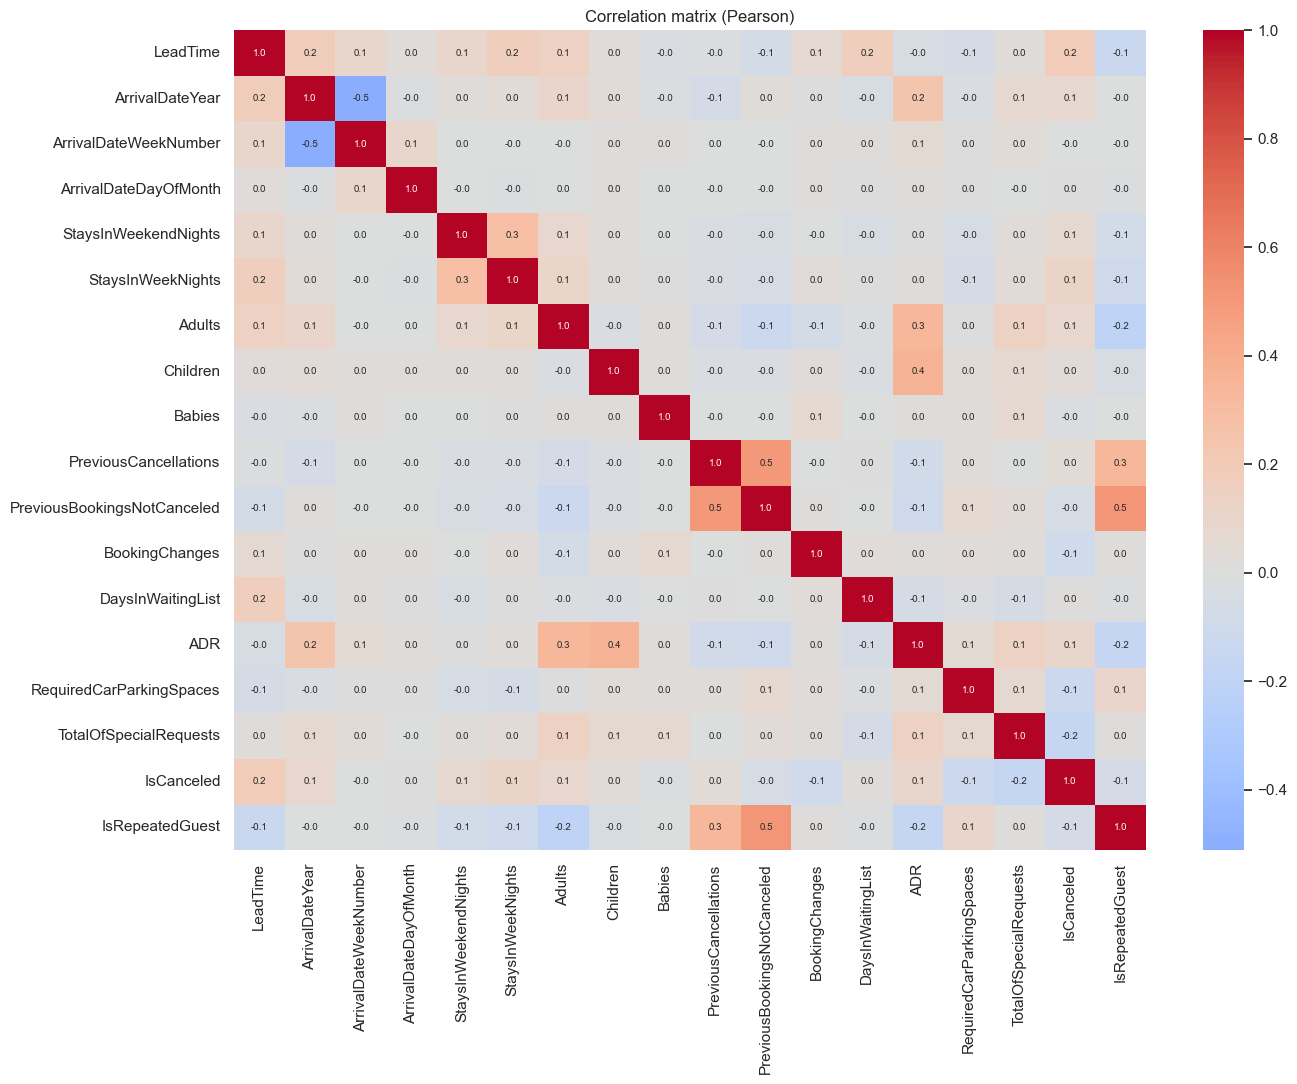

Strongest correlations with ADR:


,ADR
Children,0.360
Adults,0.340
ArrivalDateYear,0.245
IsRepeatedGuest,-0.169
TotalOfSpecialRequests,0.136
PreviousBookingsNotCanceled,-0.109


Strongest correlations with IsCanceled:


,IsCanceled
LeadTime,0.190
TotalOfSpecialRequests,-0.166
RequiredCarParkingSpaces,-0.126
StaysInWeekNights,0.112
BookingChanges,-0.092
ADR,0.087


In [13]:
# Cell 19 - correlation heatmap (numeric features + both targets)
corr = df_clean[num_cols + ['IsCanceled', 'IsRepeatedGuest']].corr()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Correlation matrix (Pearson)')
save_fig(fig, 'eda_correlation_heatmap')
plt.show()
print('Strongest correlations with ADR:')
display(corr['ADR'].drop('ADR').sort_values(key=abs, ascending=False).head(6).round(3).to_frame())
print('Strongest correlations with IsCanceled:')
display(corr['IsCanceled'].drop('IsCanceled').sort_values(key=abs, ascending=False).head(6).round(3).to_frame())

**What this does:** Pearson correlation only measures *linear* relationships between numbers, so it cannot see categorical effects.
Use it to spot redundant features (two columns nearly the same) and to see which numbers relate to each target. A very strong link to a target is a reason to ask "is this known at prediction time?" before using it.

,missing,missing_%
Company,50300,94.83
Agent,5471,10.31
Children,4,0.01
Country,3,0.01


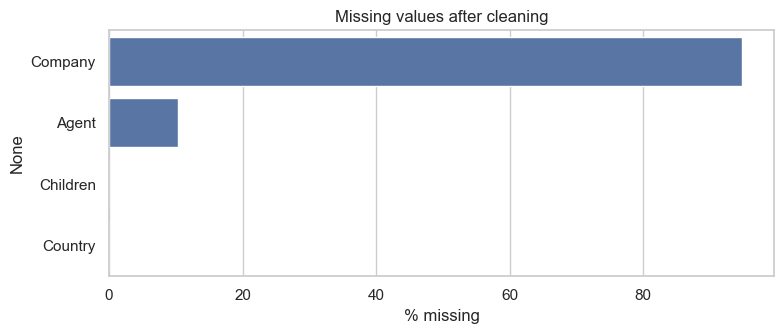

Agent
has agent    0.32
no agent     0.15
Name: IsCanceled, dtype: float64


In [14]:
# Cell 20 - missing values: how much and where
miss = df_clean.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False)
miss_pct = (miss / len(df_clean) * 100).round(2)
display(pd.DataFrame({'missing': miss, 'missing_%': miss_pct}))

if len(miss):
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.5 * len(miss) + 1.5)))
    sns.barplot(x=miss_pct.values, y=miss_pct.index, ax=ax)
    ax.set_xlabel('% missing'); ax.set_title('Missing values after cleaning')
    save_fig(fig, 'eda_missing_values')
    plt.show()
else:
    print('No missing values after cleaning - nothing to plot.')

# Is 'no agent' informative? Compare cancel rate with and without an agent.
if 'Agent' in df_clean.columns:
    print(df_clean.groupby(df_clean['Agent'].isna())['IsCanceled'].mean().rename({False: 'has agent', True: 'no agent'}).round(3))

**What this does:** lists which columns still have real NaN values (these are filled later inside the Pipeline, fitted on train only).
The last line checks whether "no agent" behaves differently from "has an agent". If the cancel rates differ, missingness itself is information, so we keep it as a category/flag instead of filling it with a typical agent ID.

## Leakage audit table (new)
**Prediction / analysis point:** the moment the booking enters the PMS (booking time). A feature is allowed only if its
value is already fixed at that moment. `USE` = known at booking, `CAUTION` = may change after booking, run with and
without it and report both, `EXCLUDE` = known only later or reveals the outcome, `TARGET` = the variable being predicted.
This table is a first draft for the report; adjust it if your team picks a different prediction point.

In [15]:
# Cell 21 - leakage audit table (nothing is removed from df_clean; this only documents decisions)
USE, CAUTION, EXCLUDE, TARGET = 'USE', 'CAUTION', 'EXCLUDE', 'TARGET'
at_booking = 'known at booking'
leak_rules = {
    # column: (when known, regression, classification, clustering, reason)
    'IsCanceled': ('after stay / cancellation', EXCLUDE, TARGET, EXCLUDE, 'The outcome itself; unknown at booking time.'),
    'ReservationStatus': ('final status', EXCLUDE, EXCLUDE, EXCLUDE, 'Canceled / Check-Out / No-Show restates the outcome (direct leakage).'),
    'ReservationStatusDate': ('final status', EXCLUDE, EXCLUDE, EXCLUDE, 'Date of the final status; with the arrival date it reveals when and whether it was canceled.'),
    'AssignedRoomType': ('at check-in', EXCLUDE, EXCLUDE, EXCLUDE, 'Assigned only at check-in; canceled bookings often never get one (indirect leakage).'),
    'BookingChanges': ('accumulates until check-in / cancellation', EXCLUDE, EXCLUDE, EXCLUDE, 'Counter that grows after booking; its final value already reflects the booking outcome.'),
    'DaysInWaitingList': ('at confirmation', CAUTION, CAUTION, CAUTION, 'Only final once the booking is confirmed; keep only if the prediction point is after confirmation.'),
    'ADR': ('quoted at booking, can be amended', TARGET, CAUTION, CAUTION, 'Rate may be adjusted later; for classification test with and without it.'),
    'RequiredCarParkingSpaces': ('requested, can change later', CAUTION, CAUTION, CAUTION, 'Can be added after booking; check how much it changes results.'),
    'TotalOfSpecialRequests': ('requested, can grow later', CAUTION, CAUTION, CAUTION, 'Requests can accumulate after booking; check how much it changes results.'),
    'DepositType': (at_booking, USE, USE, USE, 'Set at booking; note Non Refund may reflect hotel policy, explain it in the report.'),
}
for _c in ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth',
           'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country',
           'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations',
           'PreviousBookingsNotCanceled', 'ReservedRoomType', 'Agent', 'Company', 'CustomerType']:
    leak_rules[_c] = (at_booking, USE, USE, USE, 'Part of the reservation request / guest history at booking.')

leak_table = pd.DataFrame.from_dict(
    leak_rules, orient='index',
    columns=['when_known', 'regression', 'classification', 'clustering', 'reason'])
leak_table.index.name = 'column'

not_covered = [c for c in df_clean.columns if c not in leak_table.index]
not_in_data = [c for c in leak_table.index if c not in df_clean.columns]
print('Columns in data but NOT in the leakage table (decide them!):', not_covered)
print('Columns in the table but not in the data (check spelling):', not_in_data)

display(leak_table)
for task in ['regression', 'classification', 'clustering']:
    print(f'{task:15s} EXCLUDE ->', leak_table.index[leak_table[task] == EXCLUDE].tolist())
leak_table.to_csv(OUTPUT_TABLES / 'leakage_audit_table.csv')

Columns in data but NOT in the leakage table (decide them!): []
Columns in the table but not in the data (check spelling): []


,when_known,regression,classification,clustering,reason
column,,,,,
IsCanceled,after stay / cancellation,EXCLUDE,TARGET,EXCLUDE,The outcome itself; unknown at booking time.
ReservationStatus,final status,EXCLUDE,EXCLUDE,EXCLUDE,Canceled / Check-Out / No-Show restates the ou...
ReservationStatusDate,final status,EXCLUDE,EXCLUDE,EXCLUDE,Date of the final status; with the arrival dat...
AssignedRoomType,at check-in,EXCLUDE,EXCLUDE,EXCLUDE,Assigned only at check-in; canceled bookings o...
BookingChanges,accumulates until check-in / cancellation,EXCLUDE,EXCLUDE,EXCLUDE,Counter that grows after booking; its final va...
DaysInWaitingList,at confirmation,CAUTION,CAUTION,CAUTION,Only final once the booking is confirmed; keep...
ADR,"quoted at booking, can be amended",TARGET,CAUTION,CAUTION,Rate may be adjusted later; for classification...
RequiredCarParkingSpaces,"requested, can change later",CAUTION,CAUTION,CAUTION,Can be added after booking; check how much it ...
TotalOfSpecialRequests,"requested, can grow later",CAUTION,CAUTION,CAUTION,Requests can accumulate after booking; check h...


regression      EXCLUDE -> ['IsCanceled', 'ReservationStatus', 'ReservationStatusDate', 'AssignedRoomType', 'BookingChanges']
classification  EXCLUDE -> ['ReservationStatus', 'ReservationStatusDate', 'AssignedRoomType', 'BookingChanges']
clustering      EXCLUDE -> ['IsCanceled', 'ReservationStatus', 'ReservationStatusDate', 'AssignedRoomType', 'BookingChanges']


## Findings to write in the report (fill in after running)
- ADR: shape of the distribution, skew, what happens at ADR = 0.
- IsCanceled: class balance and which metrics that forces us to report.
- Which categorical features separate cancellations / ADR most clearly.
- Seasonality pattern and the date range implications for splitting.
- Features that look suspiciously strong. The first-draft leakage table is in Cell 21; confirm it against these plots.